# P15 — Composição celular por biblioteca (CLR + lm, forest plots)

**Pergunta.** A proporção de cada tipo de célula T CD4⁺ (atlas L2 de
Yasumizu et al. 2024) muda com o estímulo por *M. leprae* (NS × ML) e
entre os grupos clínicos (controle, PB, MB, NP)?

**Ponto de partida.** O objeto final do P13 (`dataReseq/analises_previas/P13_objeto_final/reseq_final.h5ad`).

**Método: o mesmo do projeto espacial**, de três referências:

| | referência | o que vem dela |
| --- | --- | --- |
| A | `spatialPaper/src/integration/composition_condition_by_resolution.R` | painéis A–E: composição com dendrograma (pvclust), média por grupo, forests C/D/E |
| B | `spatialPaper/src/integration/composition_classificacao_forest.R` | forests de classificação par a par e do estímulo dentro de cada grupo; granularidade larga + fina |
| C | `spatialPaper/src/forest_composicao/` | forest único com os dados brutos ao lado; pseudocontagem na escala de contagem; filtro de prevalência; covariáveis no `lm` |

O cálculo comum às três: proporção de cada tipo **por biblioteca** (mínimo de
30 células) → CLR → `lm(CLR ~ grupo)` por tipo → BH entre os tipos. A e B
rodam no R, com o código copiado ([functions/composicao_forest.R](../../functions/composicao_forest.R));
C roda em Python, com os módulos copiados ([functions/composicao.py](../../functions/composicao.py),
[functions/forest_composicao.py](../../functions/forest_composicao.py)).

## Adaptação: o que mudou e por quê

**Obrigatório, porque os dados são outros:**

1. **Entrada.** O R lê um `obs.csv` escrito aqui, não o objeto Seurat.
2. **Células.** Só as CD4⁺ (sem contaminante nem baixa qualidade, pela anotação do P09) e
   com rótulo do atlas: 30.002 de 35.247 (931 CD4⁺ ficam sem L2 porque o Azimuth não as chamou de CD4).
3. **Colunas.** Amostra = `library_id` (14 bibliotecas, 7 pacientes). Tipo celular =
   `atlas_L2` (18 tipos); `atlas_L1` (5 tipos) roda junto, no papel do `BroadCelltypes` de B.
   Condição de A = estímulo (referência: não estimulado). Resposta de A e classificação de B =
   `classificacao` com HNP44 = NP (no objeto o HNP44 vem como MB; B aplica a mesma regra, `^HNP` → NP).
4. **Painéis C e D.** Em A são FB × UB, um contraste binário, dentro de cada condição. Aqui a
   classificação tem 4 níveis e MB e NP têm uma biblioteca por estímulo; C e D ficam
   PB × controle dentro de NS e dentro de ML (2 × 3 bibliotecas), o único contraste binário com
   mais de uma biblioteca por lado.
5. **Pareamento.** As 14 bibliotecas são 7 pares NS/ML do mesmo paciente. O painel E é feito como
   em A (sem o paciente) e repetido como **E2, com o paciente no `lm`** (`CLR ~ estímulo + paciente`,
   6 graus de liberdade no resíduo). O modelo com covariáveis é o de C; nenhum dos três scripts
   tinha pares.
6. **Cores do estímulo.** As do resto do Reseq (azul NS, laranja ML); as de B usavam para o ML o
   mesmo vermelho do MB.
7. **Forest com IC indefinido.** Com uma biblioteca por lado (estímulo dentro do MB e do NP) o `lm`
   fica sem resíduo; o eixo do forest de A/B quebrava. Agora usa a faixa das estimativas.

**Cosmético:** tipos na ordem do atlas (não alfabética), nome da biblioteca no eixo x do
painel A (são 14, não 28), rótulos em português e vírgula decimal.

**Mantido como nas referências:** pseudocontagem 1e-6 na proporção (A e B), ≥ 30 células por
amostra, teste só de tipos com variância > 0, `emmeans::pairs(adjust = "none")`, BH dentro de cada
comparação, pvclust (CLR, correlação, Ward.D2, 1.000 réplicas, AU ≥ 95 %), formas de
significância (✱ FDR < 0,05; ◆ p < 0,05). A pseudocontagem de contagem e o filtro de prevalência
de C entram como sensibilidade, lado a lado.

**Herdado das referências, sem correção:** os forests de classificação de B usam as 14
bibliotecas juntas (cada paciente conta duas vezes, NS e ML), e MB e NP são um paciente cada.
Esses contrastes são descritivos: com 7 pacientes, só o estímulo pareado e PB × controle
admitem inferência.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from functions import config, io, issues, plotting
from functions import composicao as CP
from functions import forest_composicao as FR
from functions.droplets import run_r

NB = "analises_previas/P15_composicao"
FIG = config.FIGURES / NB
TAB = config.TABLES / NB
WORK = config.HEAVY_OUT / NB
log = issues.IssueLog(NB)
pd.set_option("display.width", 220)

## 1. Células e desenho

In [2]:
a = ad.read_h5ad(config.DATA_OUT / "analises_previas/P13_objeto_final" / "reseq_final.h5ad", backed="r")
o = a.obs
cd4 = ~o["grupo"].isin(["contaminante", "baixa qualidade"])
tem_l2 = o["atlas_L2"].notna()
cel = o.loc[cd4 & tem_l2, ["library_id", "patient", "estimulo", "atlas_L2", "atlas_L1"]].copy()
for c in cel.columns:
    cel[c] = cel[c].astype(str)
# classificação com HNP44 = NP (regra do script B: library_id começando com HNP)
cel["classificacao"] = cel["patient"].map(config.PATIENT_CLASSIFICATION)
assert cel["classificacao"].notna().all()
print(f"{len(o):,} células no objeto · {int(cd4.sum()):,} CD4⁺ · {len(cel):,} CD4⁺ com rótulo L2 "
      f"(sem L2: {int((cd4 & ~tem_l2).sum()):,})".replace(",", "."))

desenho = (cel.groupby("library_id")
              .agg(paciente=("patient", "first"), classificacao=("classificacao", "first"),
                   estimulo=("estimulo", "first"), celulas=("patient", "size"))
              .sort_values(["classificacao", "paciente", "estimulo"]))
display(desenho)
print(pd.crosstab(desenho["classificacao"], desenho["estimulo"]))

WORK.mkdir(parents=True, exist_ok=True)
io._assert_writable(WORK / "obs.csv")
cel.reset_index(names="cell").to_csv(WORK / "obs.csv", index=False)

35.247 células no objeto · 30.933 CD4⁺ · 30.002 CD4⁺ com rótulo L2 (sem L2: 931)


,paciente,classificacao,estimulo,celulas
library_id,,,,
MB34_ML,MB34,MB,estimulado,902
MB34_NS,MB34,MB,nao estimulado,1874
HNP44_ML,HNP44,NP,estimulado,1708
HNP44_NS,HNP44,NP,nao estimulado,81
PB20_ML,PB20,PB,estimulado,700
PB20_NS,PB20,PB,nao estimulado,522
PB21_ML,PB21,PB,estimulado,9178
PB21_NS,PB21,PB,nao estimulado,3441
CTH92_ML,CTH92,controle,estimulado,1223


estimulo       estimulado  nao estimulado
classificacao                            
MB                      1               1
NP                      1               1
PB                      2               2
controle                3               3


## 2. Referências A e B, no R

Roda as duas granularidades (L2 e L1). Saem, por granularidade:
`Figure_ABCDE` (A, com o E2 pareado ao lado do E), os painéis soltos, `Figure_forests_classificacao`
(B) e as tabelas `Comparisons_*`, `SampleClusters_*` e `sensibilidade_pseudocontagem_*`.

In [3]:
r = run_r("composicao_forest.R", [WORK, FIG, TAB], timeout=3600)
(WORK / "log_R.txt").write_text(r.stdout + "\n" + r.stderr)
print("\n".join(l for l in r.stderr.splitlines() if l.startswith((">>>", "Removendo", "Clusteriza"))))
for p in sorted(FIG.glob("*.png")):
    io.register(stage=NB, name=p.stem, kind="figure", path=p, description="saída de composicao_forest.R")
for p in sorted(TAB.glob("*.csv")):
    io.register(stage=NB, name=p.stem, kind="table", path=p, description="saída de composicao_forest.R")

Clusterização hierárquica: 14 amostras x 18 tipos | dist = correlation | linkage = ward.D2 | CLR = TRUE | nboot = 1000
>>> Clusters de amostras com AU >= 95%: 2
>>> atlas_L2 | C: nenhum tipo com p < 0,05
>>> atlas_L2 | D: nenhum tipo com p < 0,05
>>> atlas_L2 | E: nenhum tipo com p < 0,05
>>> atlas_L2 | E2: TnaiveAct (p=0,0082, FDR=0,15)
Clusterização hierárquica: 14 amostras x 5 tipos | dist = correlation | linkage = ward.D2 | CLR = TRUE | nboot = 1000
>>> Clusters de amostras com AU >= 95%: 2
>>> atlas_L1 | C: nenhum tipo com p < 0,05
>>> atlas_L1 | D: nenhum tipo com p < 0,05
>>> atlas_L1 | E: nenhum tipo com p < 0,05
>>> atlas_L1 | E2: nenhum tipo com p < 0,05


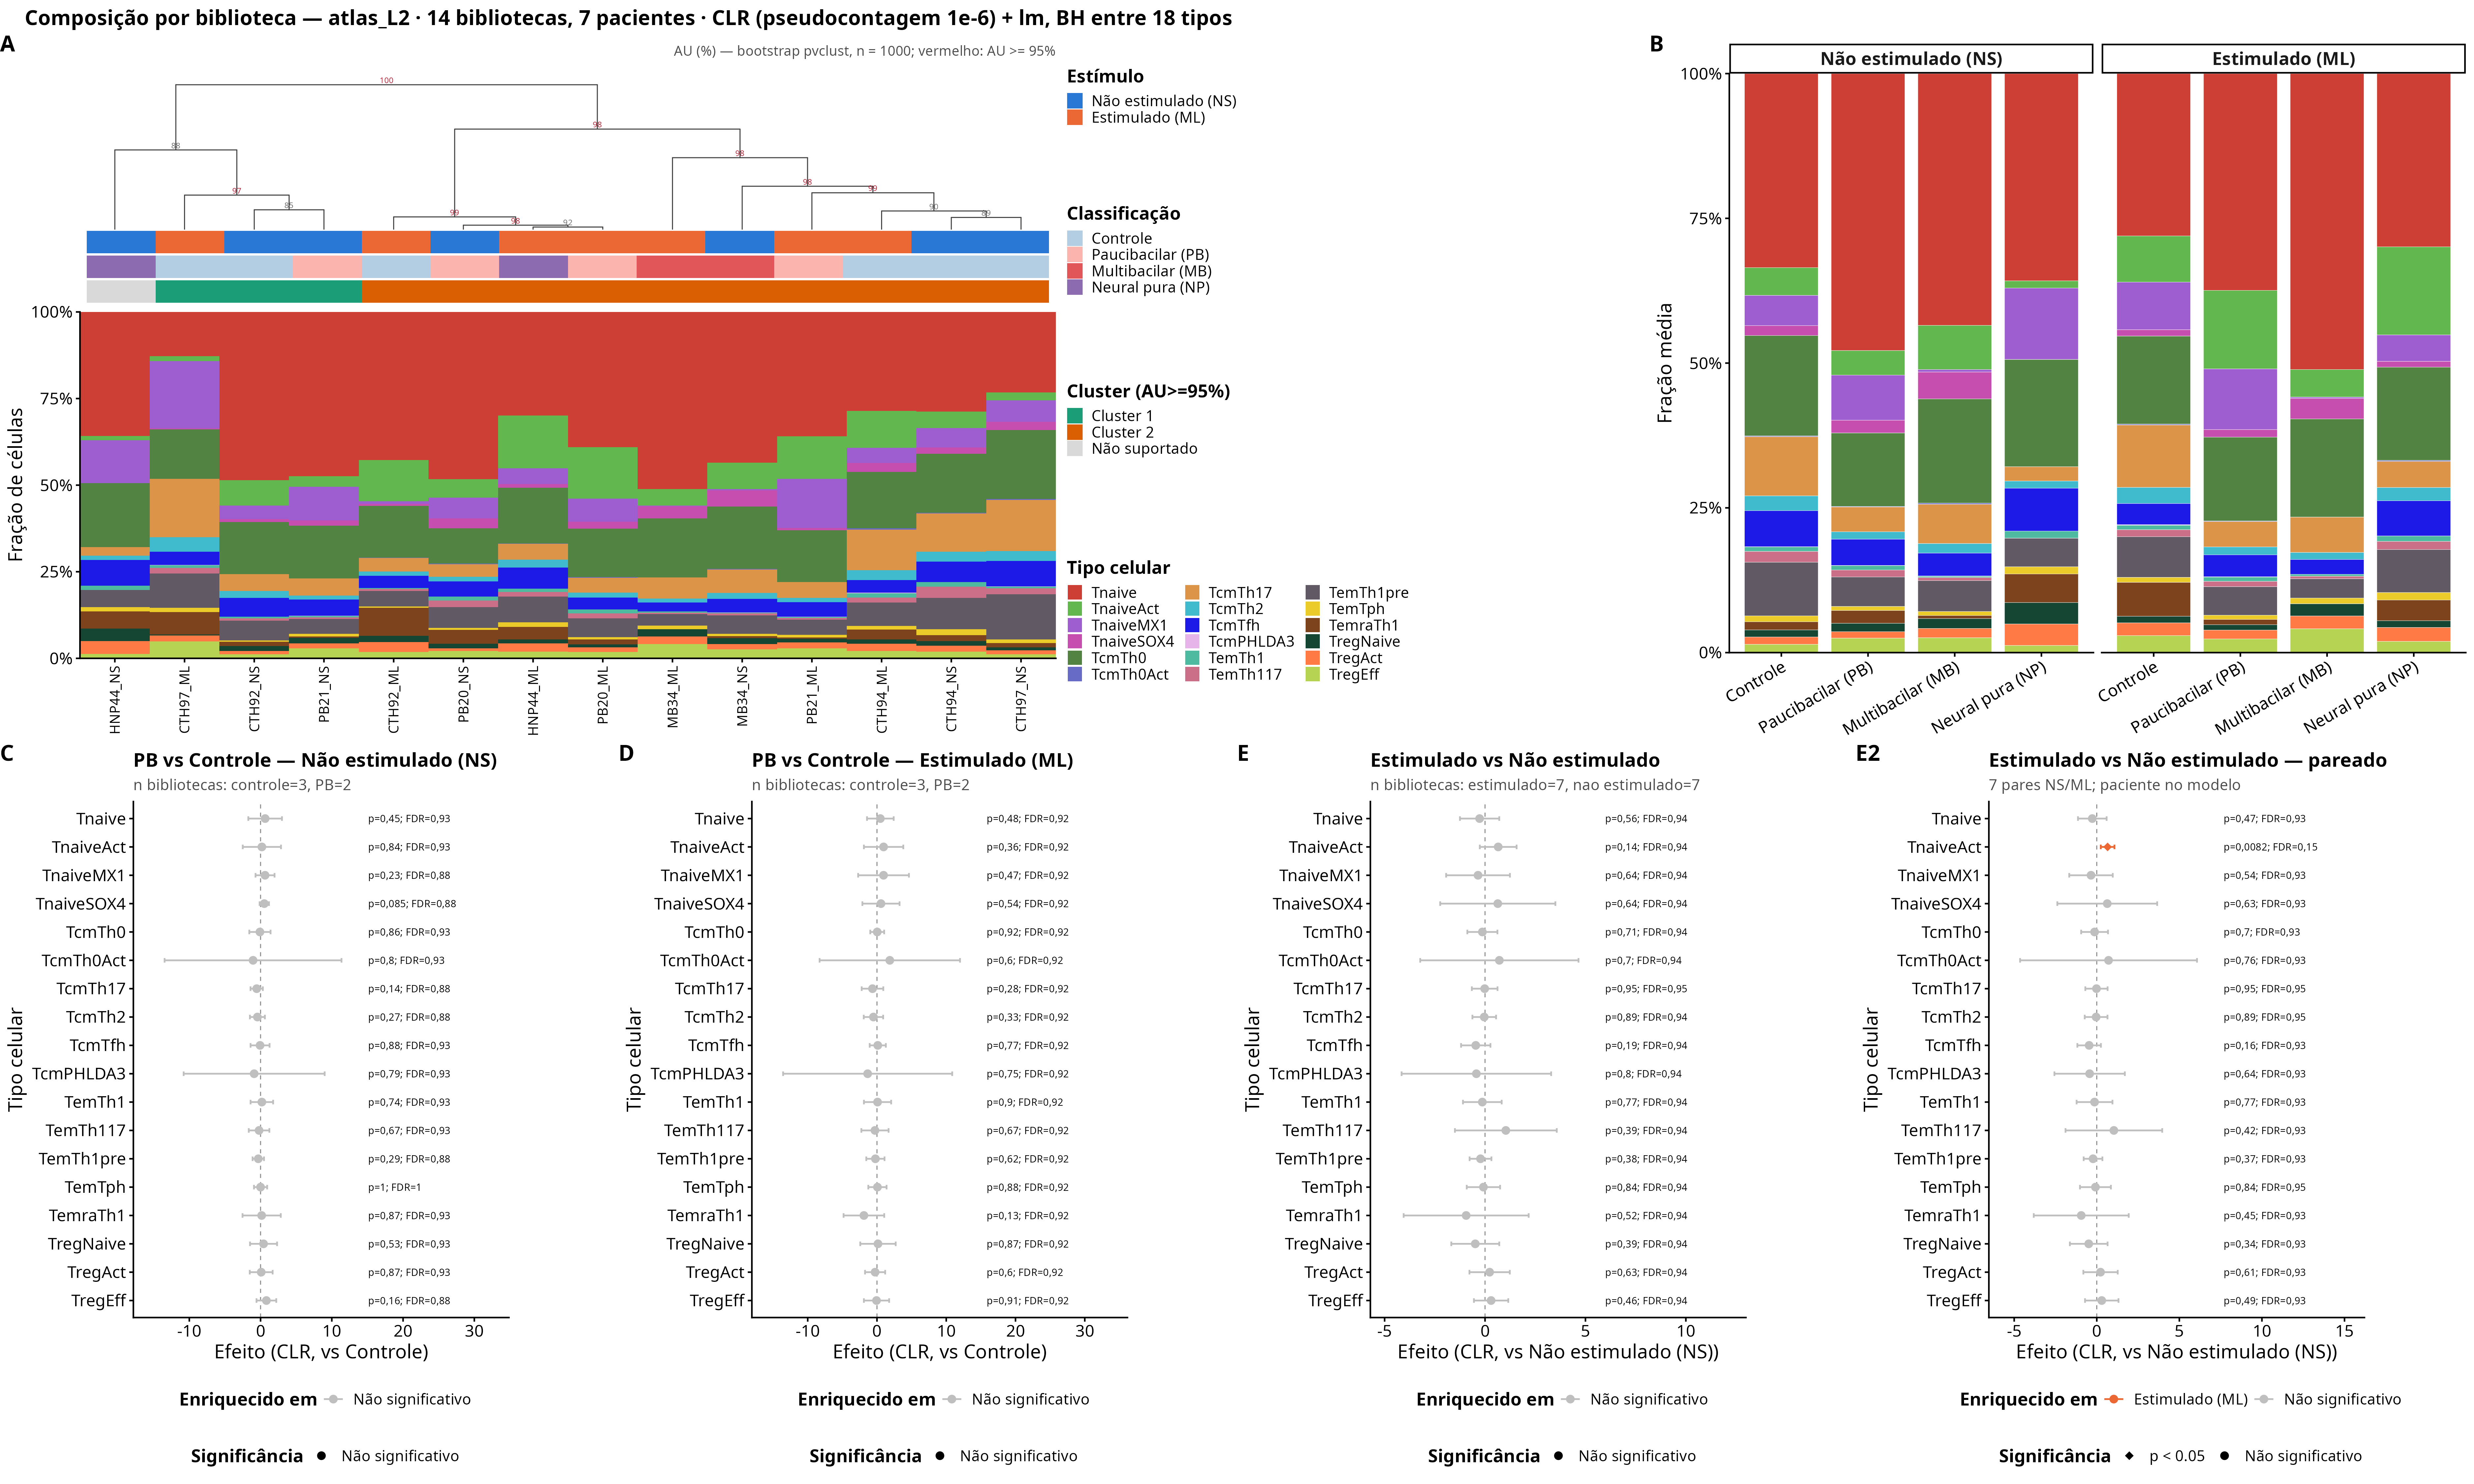

In [4]:
display(Image(filename=str(FIG / "Figure_ABCDE_atlas_L2.png"), width=1400))

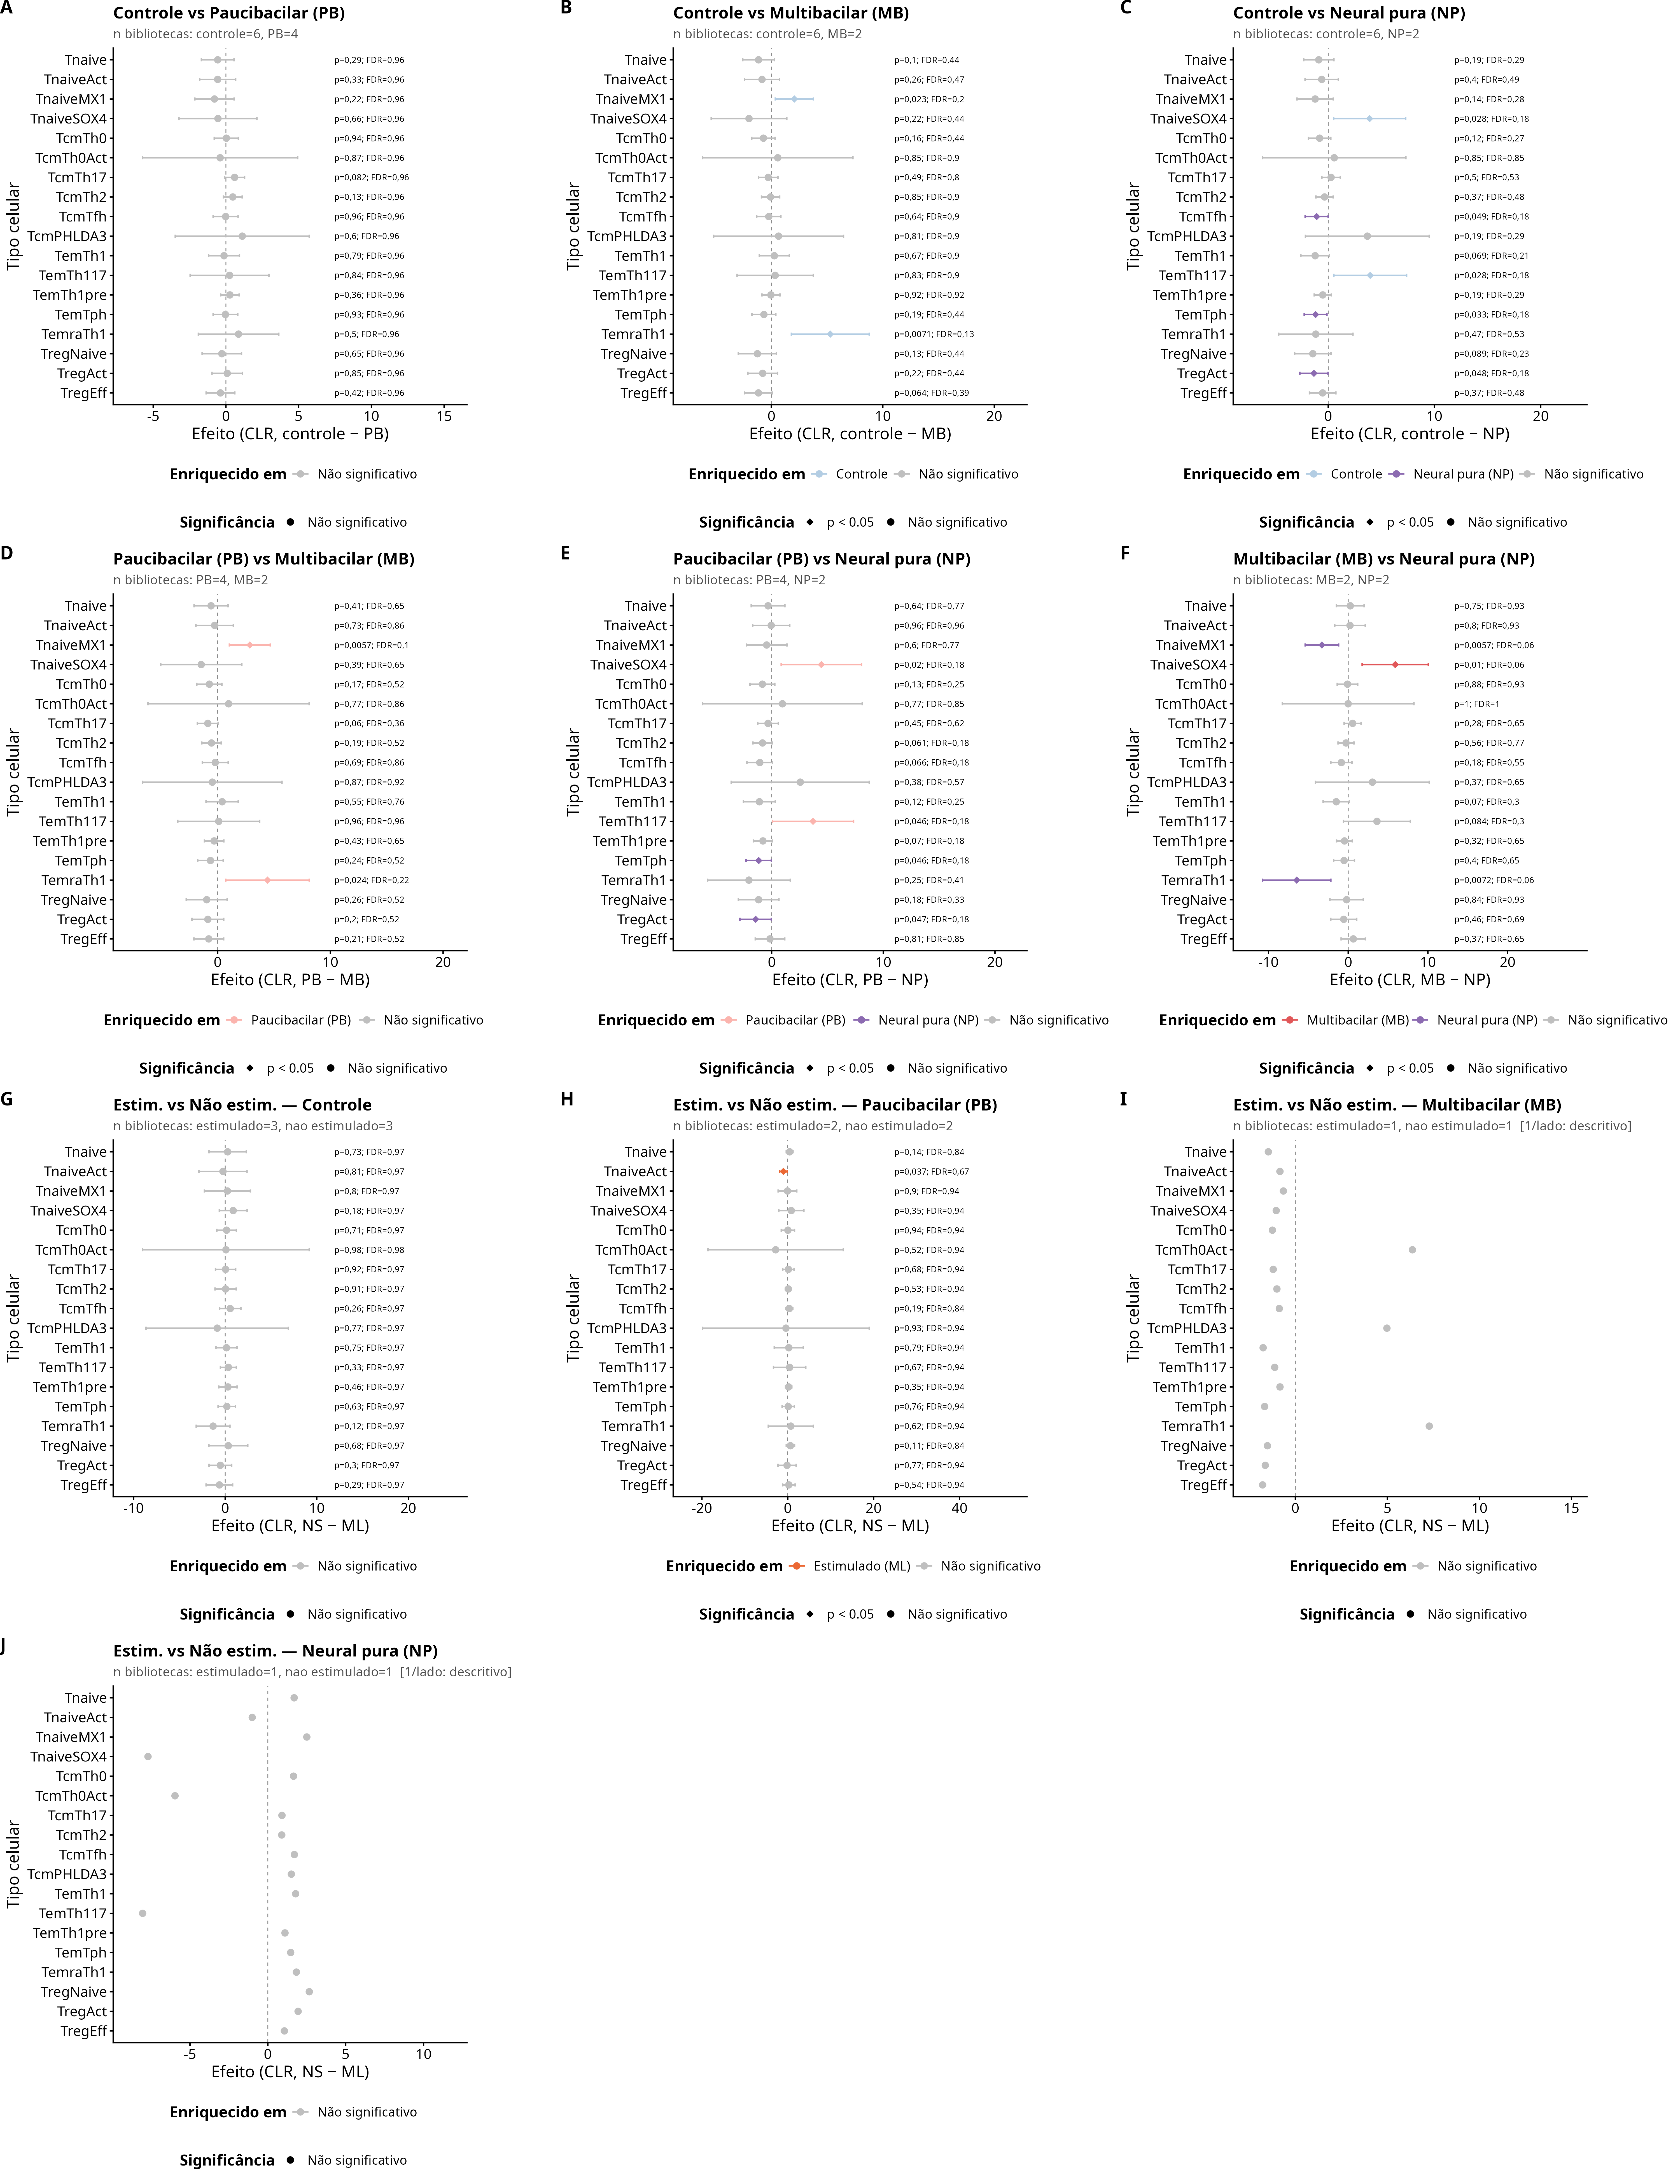

In [5]:
display(Image(filename=str(FIG / "Figure_forests_classificacao_atlas_L2.png"), width=1300))

## 3. Referência C: o contraste pareado NS × ML num forest único

O mesmo E2 (`CLR ~ estímulo + paciente`), com as duas escolhas de C: pseudocontagem na escala de
contagem, `(k + 0,5) / (N + 0,5 K)`, e filtro de prevalência (tipo presente em ≥ 1 % das células
de ≥ 3 bibliotecas de cada estímulo). Os quatro modelos são sempre calculados, como em
`run_analise.py`; a figura usa o de C (contagem + prevalência + paciente).

In [6]:
ORDEM = ["estimulado", "nao estimulado"]            # contraste ML − NS: efeito > 0 = maior em ML
CORES = {"nao estimulado": plotting.STIMULATION_COLORS["nao_estimulado"],
         "estimulado": plotting.STIMULATION_COLORS["estimulado"]}
ROT = {"nao estimulado": "não estimulado (NS)", "estimulado": "estimulado (ML)"}

saidas_c, filtros = {}, {}
for gran in ["atlas_L2", "atlas_L1"]:
    comp = CP.build_composition(cel, gran, sample_col="library_id", group_col="estimulo",
                                covars=["patient"], min_cells=30)
    filt = CP.filtro_prevalencia(comp, min_pac=3, min_frac=0.01)
    filtros[gran] = filt
    print(f"{gran}: {len(filt['testaveis'])} de {len(comp['cell_cols'])} tipos passam no filtro de "
          f"prevalência; fora: {filt['excluidos']}")
    modelos = {
        "pareado_contagem_prevalencia": dict(cell_cols=filt["testaveis"], covars=["patient"], pseudo="contagem"),
        "pareado_contagem": dict(cell_cols=None, covars=["patient"], pseudo="contagem"),
        "pareado_1e-6": dict(cell_cols=None, covars=["patient"], pseudo=1e-6),
        "sem_paciente_1e-6": dict(cell_cols=None, covars=[], pseudo=1e-6),
    }
    for nome, kw in modelos.items():
        res = CP.run_contrast(comp, ordem_grupos=ORDEM, verbose=False, **kw)
        saidas_c[(gran, nome)] = (res, comp)
        io.save_table(res, NB, f"forest_C_{gran}_{nome}", index=False,
                      description=f"CLR ~ estímulo ({nome}), {gran}, contraste ML − NS")

atlas_L2: 15 de 18 tipos passam no filtro de prevalência; fora: ['TcmPHLDA3', 'TcmTh0Act', 'TemTh1']


atlas_L1: 5 de 5 tipos passam no filtro de prevalência; fora: []


**Conferência.** O `pareado_1e-6` em Python é o E2 do R e o `sem_paciente_1e-6` é o E: as
estimativas (ML − NS nos dois) e os p têm de coincidir.

In [7]:
conf = []
for gran in ["atlas_L2", "atlas_L1"]:
    rr = pd.read_csv(TAB / f"Comparisons_{gran}_estimulo_classificacao.csv")
    for nome, cod in [("pareado_1e-6", "E2: ML vs NS, pareado por paciente"), ("sem_paciente_1e-6", "E: ML vs NS")]:
        py = saidas_c[(gran, nome)][0].set_index("cell_population")
        rv = rr[rr["comparison"] == cod].set_index("cell_population").reindex(py.index)
        conf.append({"granularidade": gran, "modelo": nome,
                     "max |Δ estimativa|": float(np.nanmax(np.abs(py["estimate"] - rv["estimate"]))),
                     "max |Δ p|": float(np.nanmax(np.abs(py["p_value"] - rv["p.value"])))})
conf = pd.DataFrame(conf)
display(conf)
assert (conf["max |Δ estimativa|"] < 1e-8).all() and (conf["max |Δ p|"] < 1e-8).all(), "R e Python divergem"

,granularidade,modelo,max |Δ estimativa|,max |Δ p|
0,atlas_L2,pareado_1e-6,6.661338e-15,4.773959e-15
1,atlas_L2,sem_paciente_1e-6,3.053113e-15,2.553513e-15
2,atlas_L1,pareado_1e-6,1.165734e-15,2.886580e-15
3,atlas_L1,sem_paciente_1e-6,1.887379e-15,1.443290e-15


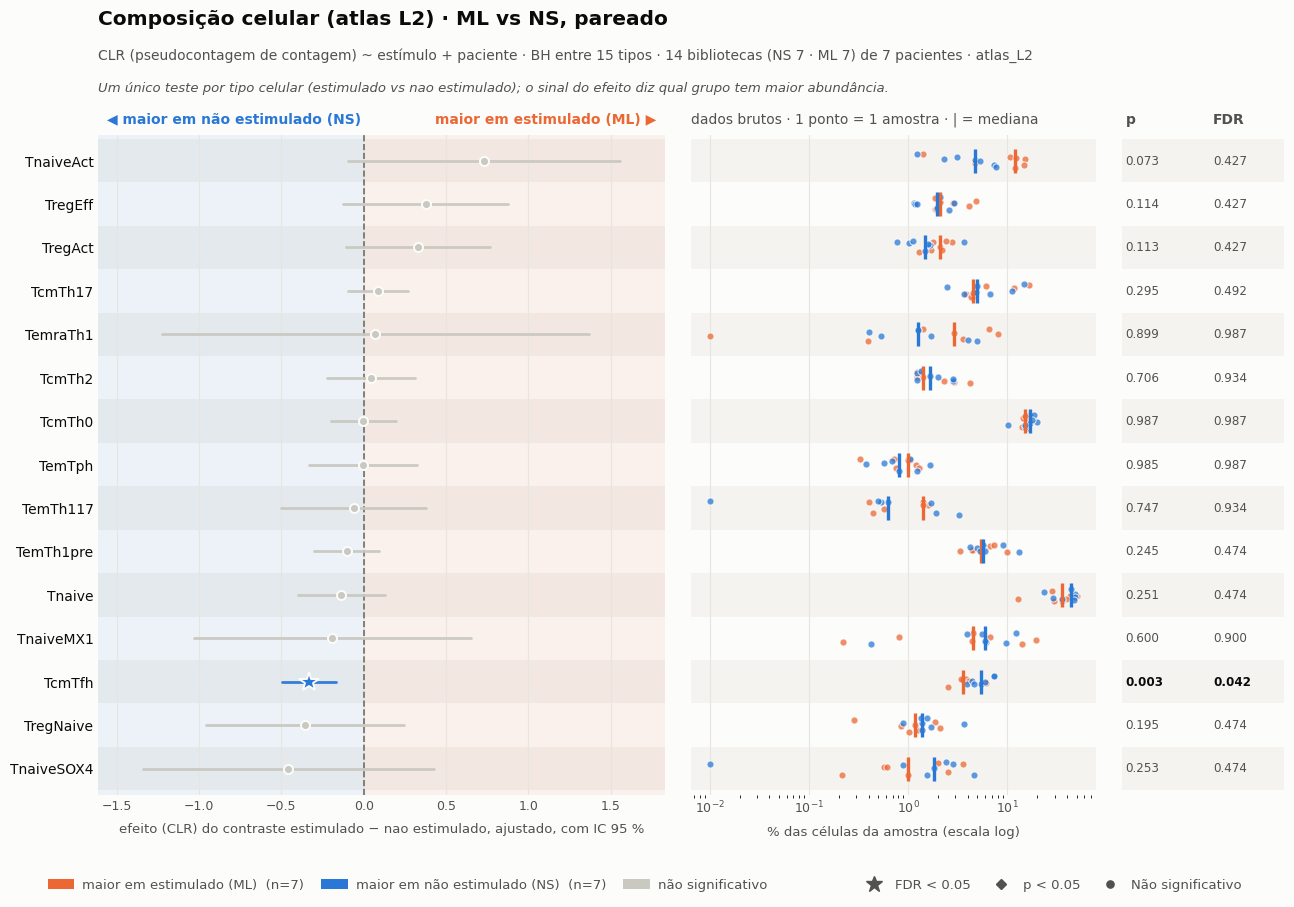

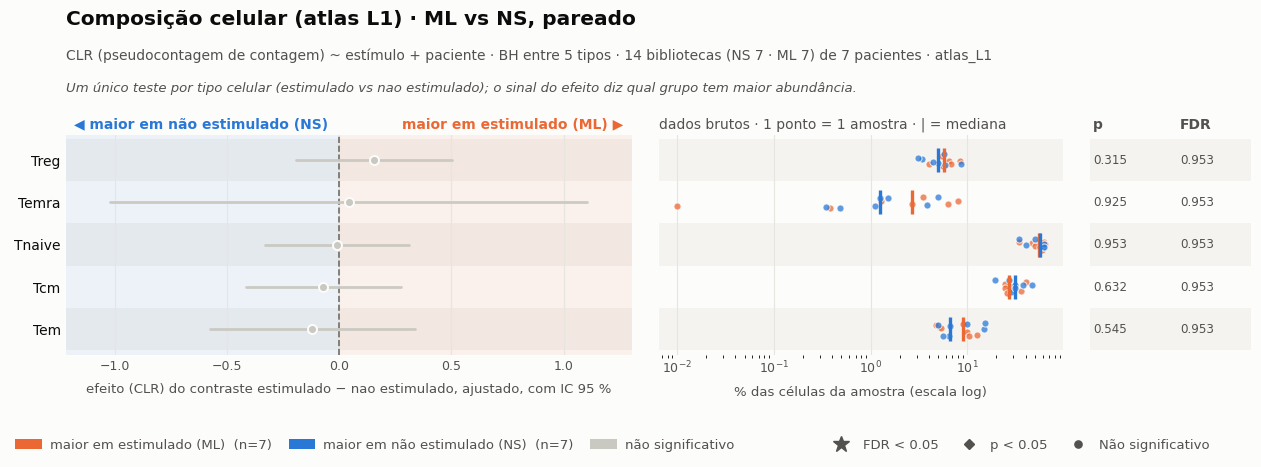

In [8]:
rot_l2 = None
for gran in ["atlas_L2", "atlas_L1"]:
    res, comp = saidas_c[(gran, "pareado_contagem_prevalencia")]
    n_ns = int((comp["meta"]["estimulo"] == "nao estimulado").sum())
    n_ml = int((comp["meta"]["estimulo"] == "estimulado").sum())
    sub = (f"CLR (pseudocontagem de contagem) ~ estímulo + paciente · BH entre {len(res)} tipos · "
           f"{res.attrs['n_amostras']} bibliotecas (NS {n_ns} · ML {n_ml}) de 7 pacientes · {gran}")
    fig, _ = FR.forest(res, comp, cores_grupo=CORES, rotulos=ROT, subtitulo=sub,
                       titulo=f"Composição celular ({gran.replace('atlas_', 'atlas ')}) · ML vs NS, pareado")
    plotting.savefig(fig, NB, f"forest_pareado_{gran}", data=res, data_index=False,
                     description=f"Forest único do contraste ML − NS pareado por paciente ({gran})")
    plt.show()

## 4. Os modelos lado a lado

FDR de cada tipo (L2) no contraste NS × ML, nos quatro modelos: o E literal das referências
(sem paciente, 1e-6), o E2 pareado com 1e-6, o pareado com a pseudocontagem de contagem, e o de C
completo (com o filtro de prevalência).

In [9]:
lado = pd.DataFrame({nome: saidas_c[("atlas_L2", nome)][0].set_index("cell_population")["FDR"]
                     for nome in ["sem_paciente_1e-6", "pareado_1e-6", "pareado_contagem", "pareado_contagem_prevalencia"]})
efeito = saidas_c[("atlas_L2", "pareado_contagem")][0].set_index("cell_population")["estimate"]
lado.insert(0, "efeito pareado (contagem)", efeito)
lado = lado.sort_values("pareado_contagem")
io.save_table(lado, NB, "comparacao_modelos_atlas_L2", description="FDR do contraste ML − NS nos quatro modelos (L2)")
display(lado.round(4))

,efeito pareado (contagem),sem_paciente_1e-6,pareado_1e-6,pareado_contagem,pareado_contagem_prevalencia
cell_population,,,,,
TcmTfh,-0.3080,0.9384,0.9257,0.2077,0.0421
TregAct,0.3550,0.9384,0.9257,0.4441,0.4274
TnaiveAct,0.7563,0.9384,0.1470,0.4441,0.4274
TregEff,0.4021,0.9384,0.9257,0.5658,0.4274
TregNaive,-0.3328,0.9384,0.9257,0.6320,0.4736
TnaiveSOX4,-0.4326,0.9384,0.9257,0.8349,0.4736
Tnaive,-0.1132,0.9384,0.9257,0.8713,0.4736
TcmTh17,0.1102,0.9525,0.9504,0.8713,0.4923
TemTh117,-0.0371,0.9384,0.9257,0.9287,0.9336


In [10]:
sens = pd.read_csv(TAB / "sensibilidade_pseudocontagem_atlas_L2.csv")
display(sens[sens["contraste"].isin(["C", "D"])].round(4))

,contraste,cell_population,estimate_1e6,p_1e6,FDR_1e6,estimate_contagem,p_contagem,FDR_contagem
0,C,Tnaive,0.6421,0.4505,0.9269,0.5433,0.3183,0.8185
1,C,TnaiveAct,0.1834,0.8418,0.9269,0.0868,0.8848,0.9607
2,C,TnaiveMX1,0.6273,0.2318,0.8788,0.5293,0.2254,0.6763
3,C,TnaiveSOX4,0.5239,0.0852,0.8788,0.4164,0.1988,0.6763
4,C,TcmTh0,-0.0888,0.8618,0.9269,-0.1847,0.6169,0.9254
5,C,TcmTh0Act,-1.0551,0.8043,0.9269,-0.6808,0.5571,0.9254
6,C,TcmTh17,-0.5441,0.1391,0.8788,-0.6340,0.2124,0.6763
7,C,TcmTh2,-0.4432,0.2719,0.8788,-0.5175,0.0204,0.3677
8,C,TcmTfh,-0.0715,0.8754,0.9269,-0.1642,0.5163,0.9254
9,C,TcmPHLDA3,-0.8997,0.7911,0.9269,0.2169,0.7246,0.9607


**Consistência entre pacientes.** O modelo pareado dá um efeito médio. Quantos dos 7 pacientes
vão no mesmo sentido? O teste do sinal (binomial exato, bilateral) não depende da pseudocontagem
nem do conjunto de tipos no CLR: com 7 pares, 7 de 7 no mesmo sentido dá p = 0,016 e 6 de 7 dá
p = 0,125.

In [11]:
from scipy.stats import binomtest

_, comp_l2 = saidas_c[("atlas_L2", "pareado_contagem")]
pm = comp_l2["proportion"].join(comp_l2["meta"][["estimulo", "patient"]])
ns = pm[pm["estimulo"] == "nao estimulado"].set_index("patient")[comp_l2["cell_cols"]]
ml = pm[pm["estimulo"] == "estimulado"].set_index("patient")[comp_l2["cell_cols"]].loc[ns.index]
sobe, desce = (ml > ns).sum(), (ml < ns).sum()
cons = pd.DataFrame({
    "pacientes ML > NS": sobe, "pacientes ML < NS": desce,
    "p do sinal": [binomtest(int(max(s, d)), int(s + d)).pvalue if s + d else np.nan for s, d in zip(sobe, desce)],
    "% mediana NS": 100 * ns.median(), "% mediana ML": 100 * ml.median(),
    "FDR pareado 1e-6": saidas_c[("atlas_L2", "pareado_1e-6")][0].set_index("cell_population")["FDR"],
    "FDR pareado C": saidas_c[("atlas_L2", "pareado_contagem_prevalencia")][0].set_index("cell_population")["FDR"],
}).sort_values("p do sinal")
io.save_table(cons, NB, "consistencia_pacientes_atlas_L2",
              description="Por tipo L2: pacientes em que ML > NS, teste do sinal e FDR dos modelos pareados")
display(cons.round(3))

,pacientes ML > NS,pacientes ML < NS,p do sinal,% mediana NS,% mediana ML,FDR pareado 1e-6,FDR pareado C
TcmTfh,0,7,0.016,5.436,3.598,0.926,0.042
TcmTh0,1,6,0.125,17.051,14.963,0.926,0.987
TemTh117,1,6,0.125,0.632,1.405,0.926,0.934
Tnaive,1,6,0.125,43.490,35.879,0.926,0.474
TregAct,6,1,0.125,1.482,2.088,0.926,0.427
TnaiveAct,5,2,0.453,4.753,11.856,0.147,0.427
TemTh1,2,5,0.453,0.518,0.783,0.926,NaN
TcmTh2,5,2,0.453,1.654,1.429,0.946,0.934
TnaiveSOX4,2,5,0.453,1.820,0.995,0.926,0.474
TemTh1pre,2,5,0.453,5.689,5.429,0.926,0.474


## 5. Interpretação

**A composição CD4⁺ no atlas L2 é estável.** O estímulo não muda nenhum tipo de forma robusta, e
o PB não difere dos controles. O que aparece depende do modelo e fica como hipótese.

**Estímulo (NS × ML).**

* No método das referências A e B (pseudocontagem 1e-6), nenhum tipo passa pelo BH. Sem o
  paciente (E), o menor p é 0,14. Com o paciente (E2), só a **TnaiveAct** tem p < 0,05
  (p = 0,008; FDR 0,15): mediana de 4,8 % em NS e 11,9 % em ML, mas sobe em 5 de 7 pacientes e cai
  no CTH97 e no MB34. Naive recém-ativada sob estímulo faz sentido; o efeito não é homogêneo.
* No modelo de C (pseudocontagem de contagem, filtro de prevalência, paciente no modelo), a
  **TcmTfh cai** com o estímulo: efeito −0,33 em CLR (cerca de ×0,7), FDR 0,042, média de 5,6 %
  para 3,9 %. É o único tipo com FDR < 0,05 em algum modelo, e cai nos **7 de 7 pacientes** (teste
  do sinal p = 0,016). Mas só cruza o FDR neste modelo: sem o filtro de prevalência o FDR é 0,21,
  e com 1e-6, 0,93. Com 18 testes, nem o sinal sobrevive ao BH (0,016 × 18 ≈ 0,28).
* **Treg**: TregAct sobe em 6 de 7 pacientes (1,5 % → 2,1 %) e TregEff em 5 de 7, ambas
  sem significância; no L1 a Treg vai de 5,2 % para 6,1 % (média), FDR 0,95. Coerente com o P14
  (razão Treg/Teff sem mudança consistente). O atlas chama de TregAct parte das células ativadas
  FOXP3⁺ Helios⁻ do estímulo.
* **Por que a pseudocontagem pesa aqui.** A matriz biblioteca × L2 tem 15 zeros, 12 deles em
  TcmPHLDA3 (17 células no total) e TcmTh0Act (29). Com 1e-6, cada zero vira log(1e-6) = −13,8:
  os IC desses tipos chegam a ±15 nos forests, e o zero desloca a média geométrica da biblioteca
  inteira, o que espalha ruído no CLR de todos os outros tipos. É o que o README do
  `forest_composicao` descreve no espacial, e por isso o E2 com 1e-6 não vê a TcmTfh, que o
  teste do sinal vê.

**PB × controle (C e D).** Nada com FDR < 0,05, em NS ou em ML, nos dois CLR. O menor p é a
TcmTh2 menor no PB em NS com a pseudocontagem de contagem (p = 0,02; FDR 0,37). Com 2 × 3
bibliotecas o poder é baixo: ausência de efeito não foi demonstrada.

**Classificação par a par (B).** Em L2 nada passa pelo BH. Os p < 0,05 estão nos contrastes com
MB ou NP e saem de zeros numa biblioteca: o MB34_ML não tem TemraTh1, e o HNP44_NS (81 células)
não tem TnaiveSOX4 nem TemTh117. Em L1 o MB aparece com mais Treg, Tnaive e Tcm e menos Temra
(FDR 0,01–0,04). Parte disso é o zero de Temra no MB34_ML: com a pseudocontagem de contagem, o
efeito da Treg cai de +1,58 para +0,94 (p = 0,005) e a Tcm deixa de ser significativa. A Treg do
MB acima dos controles repete o P14, mas é um paciente contado duas vezes (NS e ML): descritivo.

**Estímulo dentro de cada grupo (B).** Controles: a Temra (L1) é maior em ML (p = 0,022;
FDR 0,11). PB: a TnaiveAct é maior em ML (p = 0,037; FDR 0,67). MB e NP têm uma biblioteca por
lado: sem IC, só descritivo.

**Agrupamento das bibliotecas (pvclust).** As bibliotecas não se separam por estímulo nem por
grupo clínico: os ramos com AU ≥ 95 % misturam NS e ML e classificações diferentes. Com 18 tipos
como variáveis (5 em L1) o AU é pouco confiável: o BP desses mesmos ramos fica entre 0,07 e 0,43.

**Para validar.** A queda da TcmTfh (7 de 7) e a subida da TnaiveAct com o estímulo são as duas
candidatas. As duas pedem citometria ou mais pacientes antes de virar resultado.

## Problemas encontrados

In [12]:
log.add("INFO", "seção 3", "R e Python dão o mesmo resultado nos modelos em comum",
        evidence=f"max |Δ| estimativa = {conf['max |Δ estimativa|'].max():.1e}; p = {conf['max |Δ p|'].max():.1e}",
        impact="o forest de C e as figuras de A/B vêm do mesmo cálculo",
        recommendation="nenhuma")
log.add("MAJOR", "forests de classificação (B)", "classificação par a par com as 14 bibliotecas juntas",
        evidence="cada paciente entra duas vezes (NS e ML); MB e NP são 1 paciente cada",
        impact="IC e p dos contrastes de classificação são otimistas; MB e NP não generalizam",
        recommendation="ler como descritivo; para inferência, C/D (PB × controle dentro de cada estímulo)")
df_issues = log.save()
issues.show(df_issues)

severity,location,problem,evidence,impact,recommendation
MAJOR,forests de classificação (B),classificação par a par com as 14 bibliotecas juntas,cada paciente entra duas vezes (NS e ML); MB e NP são 1 paciente cada,IC e p dos contrastes de classificação são otimistas; MB e NP não generalizam,"ler como descritivo; para inferência, C/D (PB × controle dentro de cada estímulo)"
INFO,seção 3,R e Python dão o mesmo resultado nos modelos em comum,max |Δ| estimativa = 6.7e-15; p = 4.8e-15,o forest de C e as figuras de A/B vêm do mesmo cálculo,nenhuma
